# Gradient Boosting vs Random Forest — Predicting Case Duration

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

- **Random Forest** (`04_random_forest_review.ipynb`) builds many trees **independently** and averages them.
- **Gradient Boosting** builds trees **one after another**: each new tree tries to improve the mistakes made by the previous trees.

The goal is to compare Gradient Boosting with Random Forest using exactly the same data.

- **Target:** `duration_days` (same as before)
- **Features:** `events_per_case`, `unique_activities`, `unique_resources` (same as before)

## 2. Same Data

Same dataset and same completed-case logic as the previous notebooks.

In [1]:
import os
import warnings

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
warnings.filterwarnings("ignore")                 # hide an optional speed-up tip from PM4Py

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes("../data/raw/BPIC15_1.xes")
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))

Completed cases: 956


> **Limitation:** the current features describe the complete finished case. Therefore this is still a model-comparison
> exercise and **not** yet a valid early-warning model. A true early-warning model must use only information available
> before the case is completed.

In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

## 3. Same Train/Test Split

Exactly the same split as before, so all models are tested on the same 192 cases.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 4. Gradient Boosting Model

- `n_estimators=100`: the model builds **100 small trees**.
- `learning_rate=0.05`: each new tree makes only a **small correction**.
- `max_depth=2`: each individual tree stays **simple**.

In [5]:
model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 5. Evaluation

Same metrics as before: **MAE**, **RMSE** and **R²**, plus training R² vs test R².

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

train_r2 = r2_score(y_train, model.predict(X_train))
test_r2 = r2

print(f"Gradient Boosting MAE: {mae:.2f} days")
print(f"Gradient Boosting RMSE: {rmse:.2f} days")
print(f"Gradient Boosting R²: {r2:.2f}")

Gradient Boosting MAE: 51.19 days
Gradient Boosting RMSE: 104.63 days
Gradient Boosting R²: 0.49


## 6. Negative Predictions

In [7]:
print("Predictions below zero:", (y_pred < 0).sum())
print(f"Minimum predicted duration: {y_pred.min():.2f} days")

Predictions below zero: 0
Minimum predicted duration: 38.06 days


## 7. Feature Importance

Feature importance shows which variables the trees used most when making their splits. It does **not** mean that a feature
*causes* longer or shorter cases.

In [8]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,events_per_case,0.797965
1,unique_activities,0.141485
2,unique_resources,0.060549


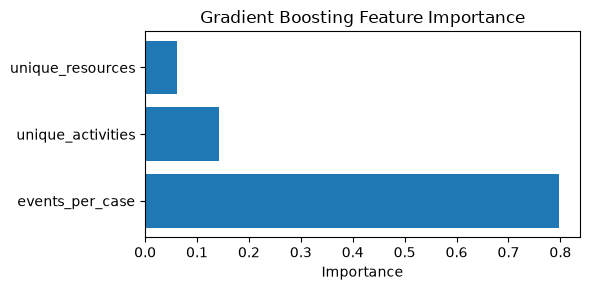

In [9]:
plt.figure(figsize=(6, 3))
plt.barh(importance["feature"], importance["importance"])
plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Actual vs Predicted

Points on the dashed line would be perfect predictions.

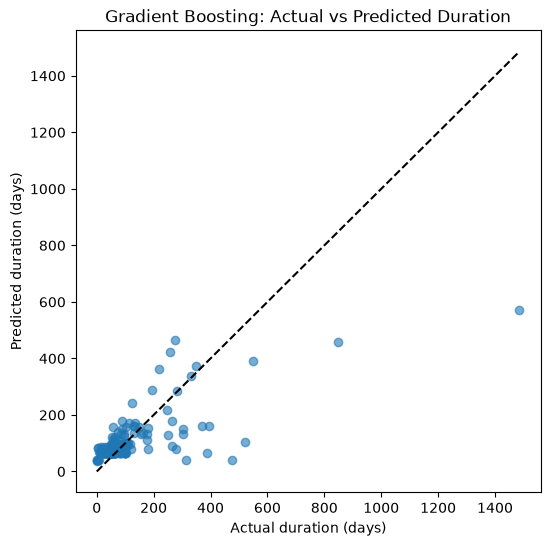

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title("Gradient Boosting: Actual vs Predicted Duration")
plt.xlabel("Actual duration (days)")
plt.ylabel("Predicted duration (days)")
plt.show()

## 9. Compare All Five Models

Previous results are taken from notebooks 02–04 (same test set). Gradient Boosting is calculated in this notebook.

In [11]:
comparison = pd.DataFrame({
    "Model": ["Mean Baseline", "Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting"],
    "MAE": [71.98, 59.01, 58.73, 52.00, mae],
    "RMSE": [147.26, 126.02, 125.50, 109.60, rmse],
    "R²": [0.00, 0.26, 0.27, 0.44, r2],
})
comparison.round(2)

,Model,MAE,RMSE,R²
0,Mean Baseline,71.98,147.26,0.00
1,Linear Regression,59.01,126.02,0.26
2,Decision Tree,58.73,125.50,0.27
3,Random Forest,52.00,109.60,0.44
4,Gradient Boosting,51.19,104.63,0.49


## 10. Overfitting Check

A large gap between training R² and test R² may indicate overfitting.
For comparison, Random Forest had training R² = 0.52 and test R² = 0.44 (a gap of 0.08).

In [12]:
print(f"Training R²: {train_r2:.2f}")
print(f"Test R²: {test_r2:.2f}")
print(f"Gap: {train_r2 - test_r2:.2f}")

Training R²: 0.46
Test R²: 0.49
Gap: -0.03


## 11. Simple Interpretation

1. **Did Gradient Boosting beat Random Forest on MAE?** Only slightly: 51.19 vs 52.00 days, less than one day better.
2. **Did it beat Random Forest on RMSE?** Yes: 104.63 vs 109.60 days, about 5 days better, so it makes somewhat smaller large errors.
3. **Did it improve R²?** Yes, a little: 0.49 vs 0.44. It explains about half of the variation in case duration.
4. **What is the train/test gap?** Training R² 0.46 vs test R² 0.49, a gap of −0.03. Test performance is not worse than
   training performance, so there is **no sign of overfitting** (Random Forest had a gap of 0.08). Test R² being slightly
   higher than training R² is most likely luck of this particular 192-case test set.
5. **Are there negative predictions?** No. The lowest prediction is 38.06 days.
6. **Which feature is most important?** `events_per_case` (about 0.80), then `unique_activities` (about 0.14) and
   `unique_resources` (about 0.06).
7. **Is the improvement meaningful or small?** **Small.** Gradient Boosting is the best model on this test set, but the
   gain over Random Forest is much smaller than the earlier jump from one Decision Tree to Random Forest. The plot looks very
   similar to Random Forest: the longest cases are still strongly under-predicted (the 1,486-day case is predicted at about 570 days).

## 12. Final Model-Comparison Conclusion

| Step | What we learned |
|---|---|
| Mean Baseline → Linear Regression | The three features contain some useful information (MAE 71.98 → 59.01 days). |
| Linear Regression → Decision Tree | One simple tree gives almost the same result and overfits. |
| Decision Tree → Random Forest | Averaging many trees gives a clear improvement (R² 0.27 → 0.44) and reduces overfitting. |
| Random Forest → Gradient Boosting | Only a small further improvement (R² 0.44 → 0.49, MAE about 1 day better). |

- Non-linear **ensemble** models (Random Forest, Gradient Boosting) clearly outperform the simple models.
- **Gradient Boosting currently performs best** on this test set (MAE 51.19 days, R² 0.49).
- The gains are getting smaller, so adding even more complex algorithms is **unlikely to help much** with only these three features.
- Even the best model still makes large errors on long cases (RMSE about 105 days), so **better features should now become the main focus**.

These results come from one train/test split, and the features describe the complete finished case. None of these
models is ready for use in SPAR.

## 13. Next Step

Move to **feature engineering** instead of adding more algorithms. The next major goal is to create features that could exist
**before** the case is finished (for example, what has happened in the first days of a case), so the project can move toward
a real early-warning model.